<a href="https://colab.research.google.com/github/Athenessa/bangkok-flood-data-analytics/blob/main/Part4_Data_Analysis_and_Insights_Revised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Part 4: Data Analysis and Insights Extraction**

## Bangkok Flooding Analysis — District-level Flood Profiles

In this part, I want to go more than just simply counting how many times flooding happened. I want to understand how flood characteristics differ across Bangkok districts, and prepare the district-level data for our K-Means clustering in Part 6.

**Our main question:**

> Do Bangkok districts show different flooding patterns in terms of frequency, persistence, rainfall, and flood depth?

I will keep the analysis connected to the raw `flood` records. The unit of analysis will change later: first we explore individual events, then we aggregate them into district-level features.

*Let's investigate this step by step eiei. 😸*

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

## 1. Load the raw data

I will use the `flood` sheet as the main source of flood-event records. The `districts` sheet will help me keep the complete list of Bangkok's 50 districts, while the `budget` sheet will be used separately for the resource-allocation exploration.

**Important:** I will not use budget variables as input features for K-Means. First, I want the clusters to represent observed flood characteristics, not the amount of budget a district receives.

In [27]:
from google.colab import drive
drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/study/Junior/Data_sci/Project/flooding_cleaned.xlsx"

df_raw = pd.read_excel(file_path, sheet_name="flood")
ds = pd.read_excel(file_path, sheet_name="districts")
bd = pd.read_excel(file_path, sheet_name="budget")

print("Flood records:", df_raw.shape)
print("District master:", ds.shape)
print("Budget records:", bd.shape)

display(df_raw.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Flood records: (841, 27)
District master: (50, 3)
Budget records: (51, 20)


,id,date,month,season,year,district,location_raw,location_raw_clean,location,location_clean,road,depth_min_cm,depth_max_cm,flood_length_m,traffic_impact,traffic_impact_no_null,start_time_text,start_time,start_time_hr,end_time_text,end_time,duration_min,duration_check,duration_over_3h,rain_mm,dup_key,dup_count
0,1,2024-03-20,3,Dry,2024,พระนคร,ถนนมหาราช วัดโพธิ์,ถนนมหาราช วัดโพธิ์,ถนนมหาราช วัดโพธิ์,ถนนมหาราช วัดโพธิ์,ถนนมหาราช,10.0,15.0,300.0,เต็มผิว,เต็มผิว,8:15 น.,08:15:00,8,8:50 น.,08:50:00,35,True,No,50.5,2024-03-20|พระนคร|ถนนมหาราช วัดโพธิ์|8:15 น.,1
1,2,2024-03-20,3,Dry,2024,ป้อมปราบศัตรูพ่าย,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า,NaN,NaN,NaN,NaN,ไม่ระบุ,8:15 น.,08:15:00,8,8:50 น.,08:50:00,35,True,No,50.5,2024-03-20|ป้อมปราบศัตรูพ่าย|ถนนเสือป่า แยกวรจ...,1
2,3,2024-03-20,3,Dry,2024,หลักสี่,ถนนแจ้งวัฒนะ ช่วงแจ้งวัฒนะซอย10,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,ถนนแจ้งวัฒนะ,10.0,15.0,100.0,1-2 เลน,1-2 เลน,9:00 น.,09:00:00,9,9:45 น.,09:45:00,45,True,No,50.0,2024-03-20|หลักสี่|ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10|9...,1
3,4,2024-03-20,3,Dry,2024,ดินแดง,ถนนประชาสงเคราะห์ ช่วงตลาดเช้า,ถนนประชาสงเคราะห์,ถนนประชาสงเคราะห์,ถนนประชาสงเคราะห์,ถนนประชาสงเคราะห์,10.0,15.0,NaN,NaN,ไม่ระบุ,8:10 น.,08:10:00,8,8:55 น.,08:55:00,45,True,No,52.5,2024-03-20|ดินแดง|ถนนประชาสงเคราะห์|8:10 น.,1
4,5,2024-03-20,3,Dry,2024,บางแค,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม,10.0,15.0,100.0,เต็มผิว,เต็มผิว,8:30 น.,08:30:00,8,9:25 น.,09:25:00,55,True,No,90.5,2024-03-20|บางแค|ถนนเพชรเกษม หน้าวัดประดู่|8:3...,1


## 2. Data checking and duplicate investigation

Before interpreting the patterns, I want to check whether the same flood event appears more than once. Duplicate events could artificially increase the flood frequency of a district.

The dataset contains a `dup_key` and `dup_count` prepared during cleaning. I will inspect those records before removing repeated entries.

In [28]:
print("Missing values:")
display(
    pd.DataFrame({
        "Missing_Count": df_raw.isna().sum(),
        "Missing_Percentage": (df_raw.isna().mean() * 100).round(2)
    }).sort_values("Missing_Percentage", ascending=False)
)

print("Duplicated IDs:", df_raw["id"].duplicated().sum())
print("Repeated dup_key values:", df_raw["dup_key"].duplicated().sum())
print("Rows belonging to repeated event keys:",
      (df_raw["dup_count"] > 1).sum())

duplicate_events = df_raw[
    df_raw["dup_key"].duplicated(keep=False)
].sort_values("dup_key")

display(
    duplicate_events[
        ["id", "date", "district", "location_clean",
         "start_time_text", "dup_key", "dup_count"]
    ]
)

Missing values:


,Missing_Count,Missing_Percentage
flood_length_m,349,41.50
traffic_impact,311,36.98
depth_max_cm,6,0.71
depth_min_cm,6,0.71
year,0,0.00
district,0,0.00
location_raw,0,0.00
season,0,0.00
id,0,0.00
date,0,0.00


Duplicated IDs: 0
Repeated dup_key values: 8
Rows belonging to repeated event keys: 16


,id,date,district,location_clean,start_time_text,dup_key,dup_count
110,111,2024-08-19,สวนหลวง,ถนนพัฒนาการแยกศรีนครินทร์,22:45 น.,2024-08-19|สวนหลวง|ถนนพัฒนาการแยกศรีนครินทร์|2...,2
111,112,2024-08-19,สวนหลวง,ถนนพัฒนาการแยกศรีนครินทร์,22:45 น.,2024-08-19|สวนหลวง|ถนนพัฒนาการแยกศรีนครินทร์|2...,2
154,155,2024-10-10,จตุจักร,ถนนพหลโยธิน ช่วงหน้าเซนทรัลลาดพร้าว,18:30 น.,2024-10-10|จตุจักร|ถนนพหลโยธิน ช่วงหน้าเซนทรัล...,2
155,156,2024-10-10,จตุจักร,ถนนพหลโยธิน ช่วงหน้าเซนทรัลลาดพร้าว,18:30 น.,2024-10-10|จตุจักร|ถนนพหลโยธิน ช่วงหน้าเซนทรัล...,2
219,220,2025-04-15,ดินแดง,ถนนดินแดง หน้าโรงเรียนพิบูลย์ฯ,18:30 น.,2025-04-15|ดินแดง|ถนนดินแดง หน้าโรงเรียนพิบูลย...,2
220,221,2025-04-15,ดินแดง,ถนนดินแดง หน้าโรงเรียนพิบูลย์ฯ,18:30 น.,2025-04-15|ดินแดง|ถนนดินแดง หน้าโรงเรียนพิบูลย...,2
273,274,2025-05-10,จตุจักร,ถนนพหลโยธินช่วงแยกเกษตร,18:05 น.,2025-05-10|จตุจักร|ถนนพหลโยธินช่วงแยกเกษตร|18:...,2
279,280,2025-05-10,จตุจักร,ถนนพหลโยธินช่วงแยกเกษตร,18:05 น.,2025-05-10|จตุจักร|ถนนพหลโยธินช่วงแยกเกษตร|18:...,2
255,256,2025-05-10,บางเขน,ถนนพหลโยธิน ช่วงหน้ากรมทหาราบที่ 11,18:05 น.,2025-05-10|บางเขน|ถนนพหลโยธิน ช่วงหน้ากรมทหารา...,2
256,257,2025-05-10,บางเขน,ถนนพหลโยธิน ช่วงหน้ากรมทหาราบที่ 11,18:05 น.,2025-05-10|บางเขน|ถนนพหลโยธิน ช่วงหน้ากรมทหารา...,2


### What I found from the duplicate check

There are **8 repeated event keys**, representing **16 rows**. This means there are 8 extra repeated records, not 16 extra events.

I will keep one record per `dup_key` for the main analysis. I will preserve `df_raw` so that the original uploaded data remains unchanged.

This is important because all frequency and district-level calculations should be based on the same deduplicated dataset.

In [29]:
df = df_raw.drop_duplicates(subset="dup_key", keep="first").copy()

print("Original records:", len(df_raw))
print("Records after deduplication:", len(df))
print("Removed repeated rows:", len(df_raw) - len(df))

print("Remaining duplicated event keys:",
      df["dup_key"].duplicated().sum())

df["date"] = pd.to_datetime(df["date"])

Original records: 841
Records after deduplication: 833
Removed repeated rows: 8
Remaining duplicated event keys: 0


## 3. Temporal analysis

### Which months have the highest number of recorded flooding events?

I will first look at the monthly distribution. This helps me understand when flooding is most frequently recorded in the dataset.

However, the number of recorded events does not automatically represent the actual probability of flooding. Reporting coverage and the observation period may also affect the counts.

In [30]:
monthly_events = (
    df.groupby("month")
    .size()
    .reindex(range(1, 13), fill_value=0)
    .reset_index(name="flood_events")
)

display(monthly_events)

,month,flood_events
0,1,0
1,2,3
2,3,10
3,4,12
4,5,214
5,6,49
6,7,34
7,8,55
8,9,171
9,10,155


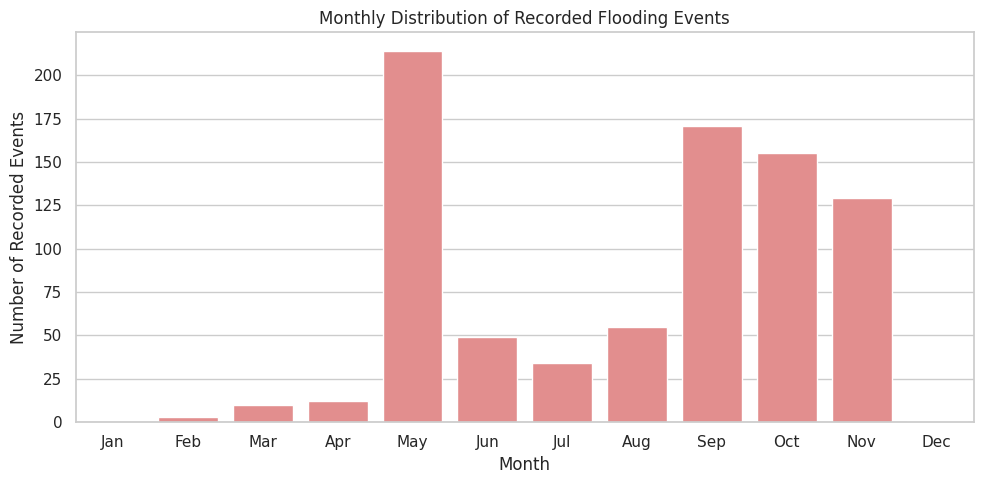

In [31]:
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(10, 5))
sns.barplot(data=monthly_events, x="month", y="flood_events",
            color="lightcoral")
plt.title("Monthly Distribution of Recorded Flooding Events")
plt.xlabel("Month")
plt.ylabel("Number of Recorded Events")
plt.xticks(range(12), month_labels)
plt.tight_layout()
plt.show()

**Initial insight:** May has the highest number of recorded events in this dataset. September, October, and November also show relatively high counts.

This suggests that recorded flooding is concentrated in particular months. I still need to compare this with rainfall and seasonal patterns before making a stronger environmental interpretation.

Also, I want to remember that the dataset covers two years only, so this is not enough to establish a long-term climate trend.

### How does flooding duration vary across months?

Counting events tells me how frequently flooding is recorded, but it does not tell me whether those events last for a long time.

I will compare mean duration, median duration, and the percentage of events lasting over three hours. I include the median because a few very long events can pull the mean upward.

In [32]:
monthly_duration = (
    df.groupby("month")
    .agg(
        flood_events=("id", "count"),
        mean_duration=("duration_min", "mean"),
        median_duration=("duration_min", "median"),
        max_duration=("duration_min", "max"),
        over_3h=("duration_over_3h",
                 lambda x: (x == "Yes").sum())
    )
    .reindex(range(1, 13))
    .rename_axis("month")
    .reset_index()
)

monthly_duration["over_3h_pct"] = (
    monthly_duration["over_3h"]
    / monthly_duration["flood_events"] * 100
)

display(monthly_duration.round(2))

,month,flood_events,mean_duration,median_duration,max_duration,over_3h,over_3h_pct
0,1,NaN,NaN,NaN,NaN,NaN,NaN
1,2,3.0,40.00,30.0,65.0,0.0,0.00
2,3,10.0,62.50,57.5,135.0,0.0,0.00
3,4,12.0,52.50,42.5,105.0,0.0,0.00
4,5,214.0,149.56,100.0,830.0,54.0,25.23
5,6,49.0,120.41,100.0,420.0,13.0,26.53
6,7,34.0,120.21,52.5,900.0,5.0,14.71
7,8,55.0,84.35,55.0,315.0,8.0,14.55
8,9,171.0,167.40,105.0,955.0,44.0,25.73
9,10,155.0,111.19,80.0,705.0,19.0,12.26


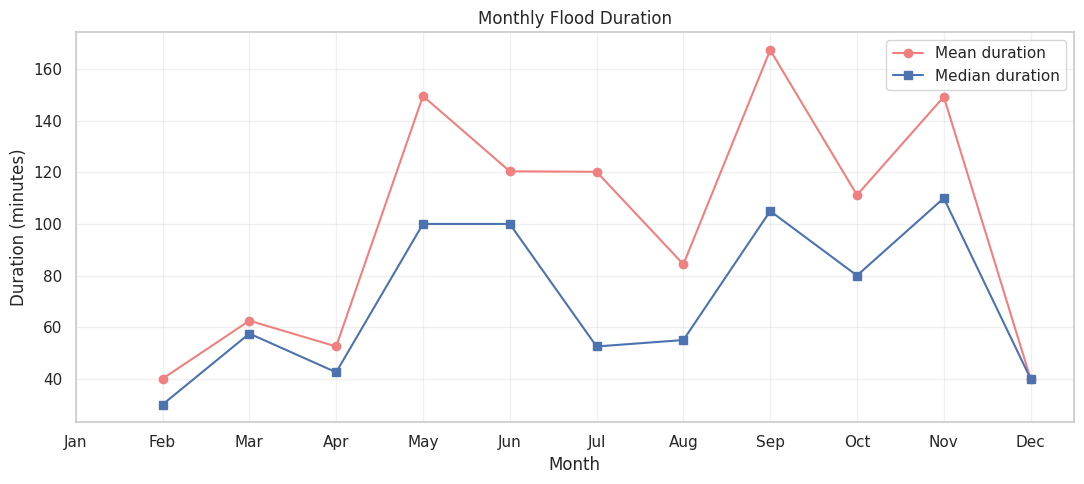

In [33]:
plt.figure(figsize=(11, 5))
plt.plot(monthly_duration["month"], monthly_duration["mean_duration"],
         marker="o", color="lightcoral", label="Mean duration")
plt.plot(monthly_duration["month"], monthly_duration["median_duration"],
         marker="s", label="Median duration")

plt.title("Monthly Flood Duration")
plt.xlabel("Month")
plt.ylabel("Duration (minutes)")
plt.xticks(range(1, 13), month_labels)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**How I interpret this:** If the mean is much higher than the median in a month, it may indicate that a smaller number of long-lasting events are influencing the average.

I will use the `over_3h_pct` column as another way to compare persistence. This percentage is more comparable across months than the raw number of long events, although months with very few observations should still be interpreted carefully.

### Does flooding differ between rainy and dry seasons?

I want to compare not only the number of events but also their duration. This helps me see whether the rainy season has more recorded events, longer events, or both.

In [34]:
seasonal_analysis = (
    df.groupby("season")
    .agg(
        flood_events=("id", "count"),
        mean_duration=("duration_min", "mean"),
        median_duration=("duration_min", "median"),
        over_3h=("duration_over_3h",
                 lambda x: (x == "Yes").sum())
    )
    .reset_index()
)

seasonal_analysis["over_3h_pct"] = (
    seasonal_analysis["over_3h"]
    / seasonal_analysis["flood_events"] * 100
)

display(seasonal_analysis.round(2))

,season,flood_events,mean_duration,median_duration,over_3h,over_3h_pct
0,Dry,155,133.37,90.0,34,21.94
1,Rainy,678,136.42,85.0,143,21.09


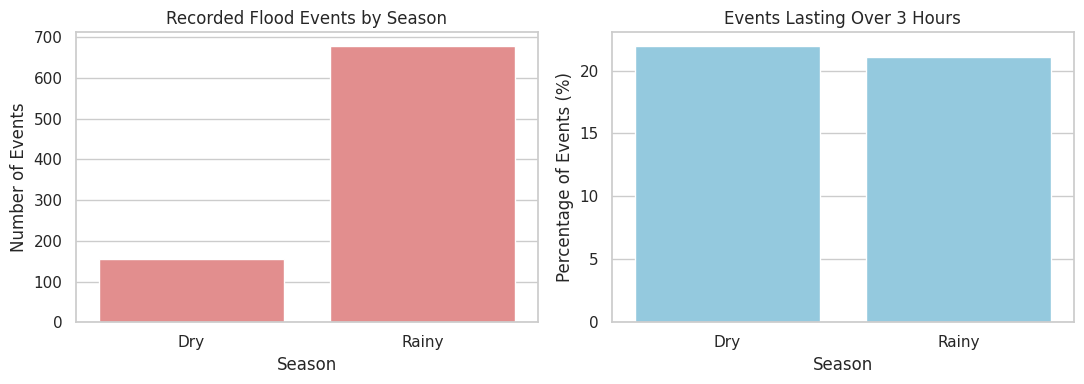

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.barplot(data=seasonal_analysis, x="season", y="flood_events",
            color="lightcoral", ax=axes[0])
axes[0].set_title("Recorded Flood Events by Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Number of Events")

sns.barplot(data=seasonal_analysis, x="season", y="over_3h_pct",
            color="skyblue", ax=axes[1])
axes[1].set_title("Events Lasting Over 3 Hours")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Percentage of Events (%)")

plt.tight_layout()
plt.show()

**Initial insight:** Most recorded events occur during the rainy season. In this dataset, 678 of 833 deduplicated records are labelled `Rainy` (about 81.4%).

This supports the observation that recorded flooding is concentrated in the rainy season. It does not, by itself, prove that rainfall is the only reason for the difference. I will examine the relationship between rainfall and other flood characteristics later.

### Are the monthly patterns consistent between 2024 and 2025?

The number of records differs between years, so I want to compare the monthly patterns rather than interpreting the total counts as a direct year-to-year change in flood risk.

In [36]:
yearly_monthly = (
    df.groupby(["year", "month"])
    .size()
    .reset_index(name="flood_events")
)

monthly_comparison = yearly_monthly.pivot(
    index="month", columns="year", values="flood_events"
).reindex(range(1, 13)).fillna(0)

display(monthly_comparison)

year,2024,2025
month,,
1,0.0,0.0
2,0.0,3.0
3,10.0,0.0
4,0.0,12.0
5,36.0,178.0
6,15.0,34.0
7,14.0,20.0
8,41.0,14.0
9,21.0,150.0


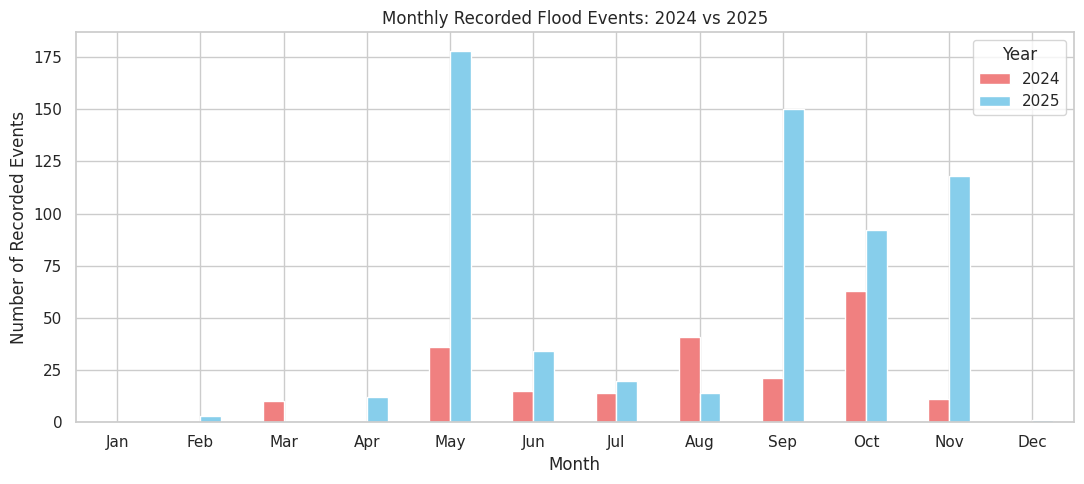

In [37]:
ax = monthly_comparison.plot(
    kind="bar", figsize=(11, 5),
    color=["lightcoral", "skyblue"]
)

ax.set_title("Monthly Recorded Flood Events: 2024 vs 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Recorded Events")
ax.set_xticklabels(month_labels, rotation=0)
ax.legend(title="Year")
plt.tight_layout()
plt.show()

**Important limitation:** The deduplicated dataset contains 211 records in 2024 and 622 in 2025. Because the number of observations differs substantially, I should not conclude that flooding became more frequent in 2025 based on these counts alone.

The comparison is useful for seeing how the recorded monthly distribution differs between the two years, but reporting coverage and data collection consistency need to be considered.

\# 4. District-level analysis — preparing for K-Means

Now I want to shift from individual flood events to district-level patterns.

Our ML direction is **District-level Flood Risk Clustering using K-Means**. Therefore, each row in the feature table should represent one district, not one flood event.

I will summarize the flood records using characteristics that describe different dimensions:

- **Frequency:** how many events were recorded.
- **Persistence:** how often events lasted over three hours and the average duration.
- **Intensity:** average rainfall and flood depth.
- **Spatial extent:** average reported flooded road length.

I will first aggregate the event records, then merge the result with the list of 50 districts.

In [38]:
district_features = (
    df.groupby("district")
    .agg(
        flood_events=("id", "count"),
        events_over_3h=("duration_over_3h",
                       lambda x: (x == "Yes").sum()),
        avg_rainfall=("rain_mm", "mean"),
        avg_min_depth=("depth_min_cm", "mean"),
        avg_max_depth=("depth_max_cm", "mean"),
        avg_flood_length=("flood_length_m", "mean"),
        flood_length_observations=("flood_length_m", "count"),
        avg_duration=("duration_min", "mean"),
        median_duration=("duration_min", "median")
    )
    .reset_index()
)

district_features["pct_events_over_3h"] = (
    district_features["events_over_3h"]
    / district_features["flood_events"] * 100
)

district_features = district_features.sort_values(
    "flood_events", ascending=False
)

display(district_features.round(2))

,district,flood_events,events_over_3h,avg_rainfall,avg_min_depth,avg_max_depth,avg_flood_length,flood_length_observations,avg_duration,median_duration,pct_events_over_3h
6,ดินแดง,56,10,60.38,11.70,17.23,269.64,28,104.55,80.0,17.86
41,หลักสี่,52,4,66.09,9.04,14.23,240.00,30,82.37,70.0,7.69
3,จตุจักร,47,14,73.94,11.32,16.66,317.39,23,133.09,100.0,29.79
21,บึงกุ่ม,45,7,49.83,11.67,16.56,219.05,21,107.89,85.0,15.56
11,บางกะปิ,44,16,73.78,9.43,14.43,211.54,26,188.14,135.5,36.36
31,ราชเทวี,41,3,69.22,10.85,16.10,200.95,21,71.22,60.0,7.32
1,คลองเตย,36,2,67.69,11.11,15.75,430.95,21,82.22,77.5,5.56
40,สายไหม,35,3,54.43,11.43,17.19,259.09,22,68.80,40.0,8.57
33,ลาดกระบัง,35,10,57.73,11.03,16.03,288.64,22,185.09,140.0,28.57
36,วัฒนา,34,1,57.51,12.21,16.91,401.85,27,74.41,62.5,2.94


### Which districts have the highest number of recorded flood events?

I will start with frequency because it gives a first view of where the dataset records more flooding events.

But I do not want to label the district with the highest count as automatically having the highest flood risk. A higher count may also reflect exposure, reporting, or observation differences.

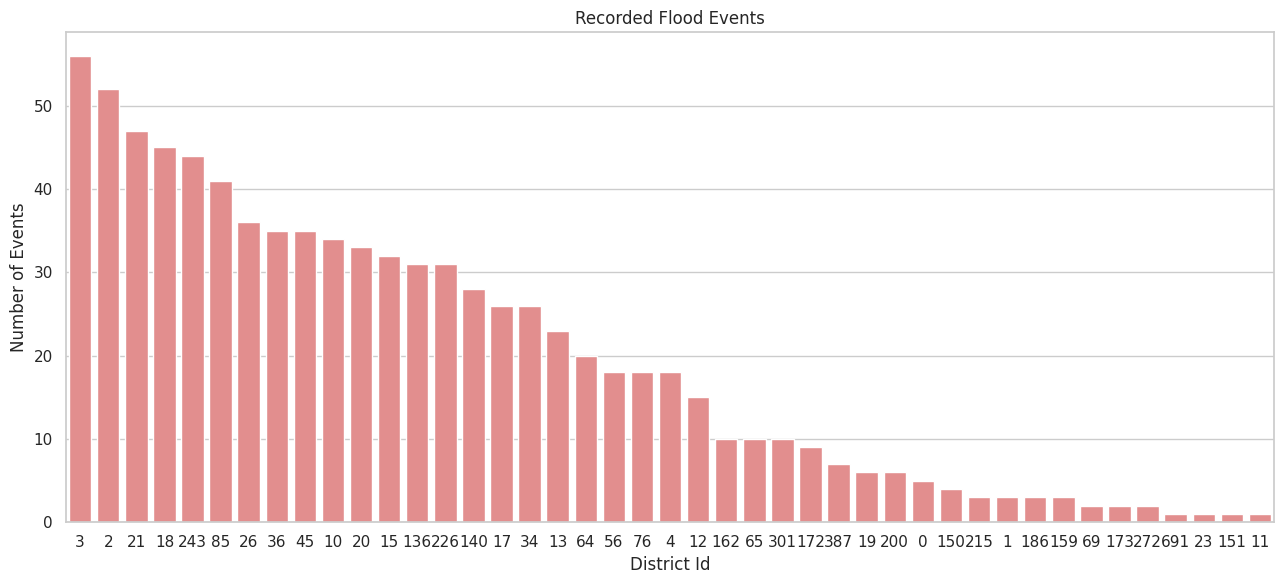

,index,district,flood_events
0,3,ดินแดง,56
1,2,หลักสี่,52
2,21,จตุจักร,47
3,18,บึงกุ่ม,45
4,243,บางกะปิ,44
5,85,ราชเทวี,41
6,26,คลองเตย,36
7,36,สายไหม,35
8,45,ลาดกระบัง,35
9,10,วัฒนา,34


In [57]:
district_first_index = df_raw.reset_index().groupby("district")["index"].first().reset_index()

district_features_with_raw_idx = district_features.merge(district_first_index, on="district", how="left")

plt.figure(figsize=(13, 6))
sns.barplot(
    data=district_features_with_raw_idx,
    x="index", y="flood_events",
    order=district_features_with_raw_idx["index"],
    color="lightcoral"
)
plt.title("Recorded Flood Events")
plt.xlabel("District Id")
plt.ylabel("Number of Events")
plt.tight_layout()
plt.show()

display(district_features_with_raw_idx[
    ["index", "district", "flood_events"]
].head(10))

**Initial insight:** Din Daeng, Lak Si, and Chatuchak have the highest recorded event counts after removing repeated event records.

This tells me where more events are recorded in the current dataset. It does not establish why those districts have higher counts, so I will compare frequency with duration and flood characteristics next.

### Do districts with more events also experience more prolonged flooding?

This is an important question for the clustering objective. A district with many short events may have a different flooding profile from a district with fewer events but a high proportion of long-lasting events.

I will compare both the number and percentage of events lasting over three hours.

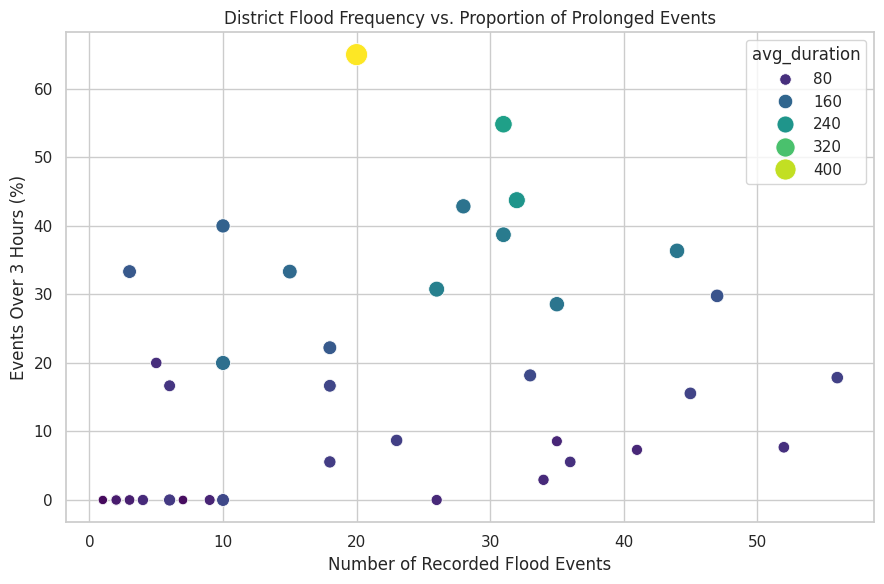

,district,flood_events,events_over_3h,pct_events_over_3h,avg_duration
5,ดอนเมือง,20,13,65.00,438.00
34,ลาดพร้าว,31,17,54.84,257.42
23,ประเวศ,32,14,43.75,239.97
42,ห้วยขวาง,28,12,42.86,182.68
12,บางขุนเทียน,10,4,40.00,152.70
35,วังทองหลาง,31,12,38.71,195.06
11,บางกะปิ,44,16,36.36,188.14
24,ป้อมปราบศัตรูพ่าย,3,1,33.33,91.67
27,พระโขนง,15,5,33.33,166.73
13,บางคอแหลม,3,1,33.33,139.00


In [40]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=district_features,
    x="flood_events",
    y="pct_events_over_3h",
    size="avg_duration",
    sizes=(40, 250),
    hue="avg_duration",
    palette="viridis"
)
plt.title("District Flood Frequency vs. Proportion of Prolonged Events")
plt.xlabel("Number of Recorded Flood Events")
plt.ylabel("Events Over 3 Hours (%)")
plt.tight_layout()
plt.show()

display(
    district_features[
        ["district", "flood_events", "events_over_3h",
         "pct_events_over_3h", "avg_duration"]
    ].sort_values("pct_events_over_3h", ascending=False).head(10).round(2)
)

**How I interpret this:** The percentage of prolonged events helps distinguish districts with different persistence patterns, even when their total event counts are not the same.

For example, a district may have fewer recorded events but a higher proportion of events lasting over three hours. This is why I should not use event frequency as the only indicator of district flood characteristics.

For K-Means, I will consider both frequency and persistence, while checking that the features do not simply duplicate one another.

### How do average flood depth, rainfall, and duration differ among districts?

I want to see whether districts with higher average flood depth also tend to have longer average durations, and whether average rainfall moves together with average depth.

These are associations in the observed records, not proof of cause and effect.

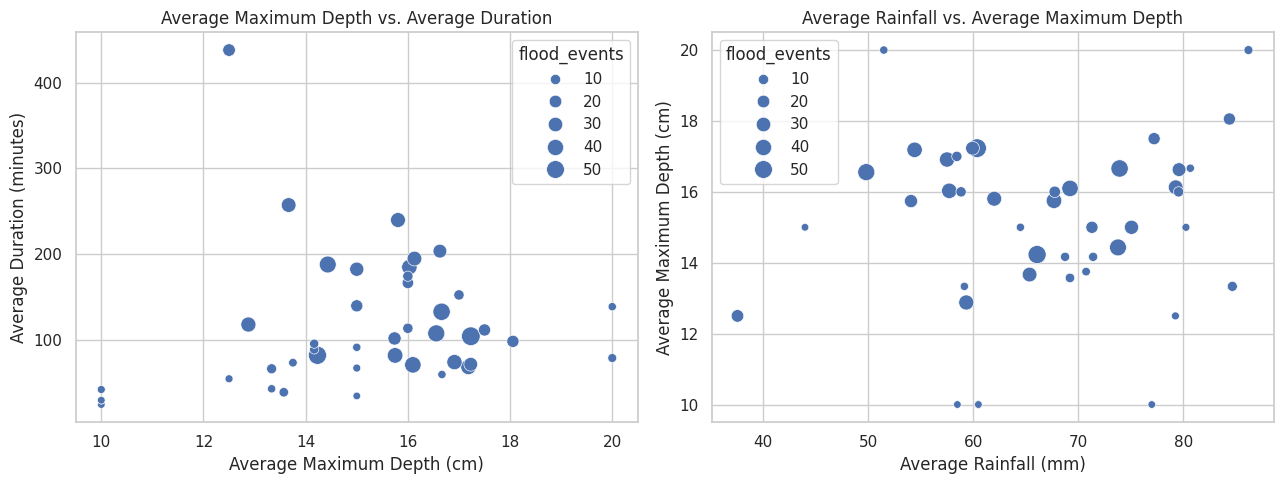

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=district_features,
    x="avg_max_depth", y="avg_duration",
    size="flood_events", sizes=(30, 180),
    ax=axes[0]
)
axes[0].set_title("Average Maximum Depth vs. Average Duration")
axes[0].set_xlabel("Average Maximum Depth (cm)")
axes[0].set_ylabel("Average Duration (minutes)")

sns.scatterplot(
    data=district_features,
    x="avg_rainfall", y="avg_max_depth",
    size="flood_events", sizes=(30, 180),
    ax=axes[1]
)
axes[1].set_title("Average Rainfall vs. Average Maximum Depth")
axes[1].set_xlabel("Average Rainfall (mm)")
axes[1].set_ylabel("Average Maximum Depth (cm)")

plt.tight_layout()
plt.show()

**What I want to look for:** districts that do not follow the general pattern. For example, a district may have a relatively high average depth but a shorter average duration, or relatively high rainfall but a moderate average depth.

These differences may help explain why the districts form different profiles in the later clustering analysis.

## 5. Correlation between district-level features

Before selecting the K-Means inputs, I want to check whether some features are strongly related.

I will use Spearman correlation as an initial check because it measures monotonic relationships and is less dependent on a linear relationship.

One thing to remember: the count of events over three hours will naturally tend to increase when a district has more total events. That is why I created `pct_events_over_3h` as a relative measure as well.

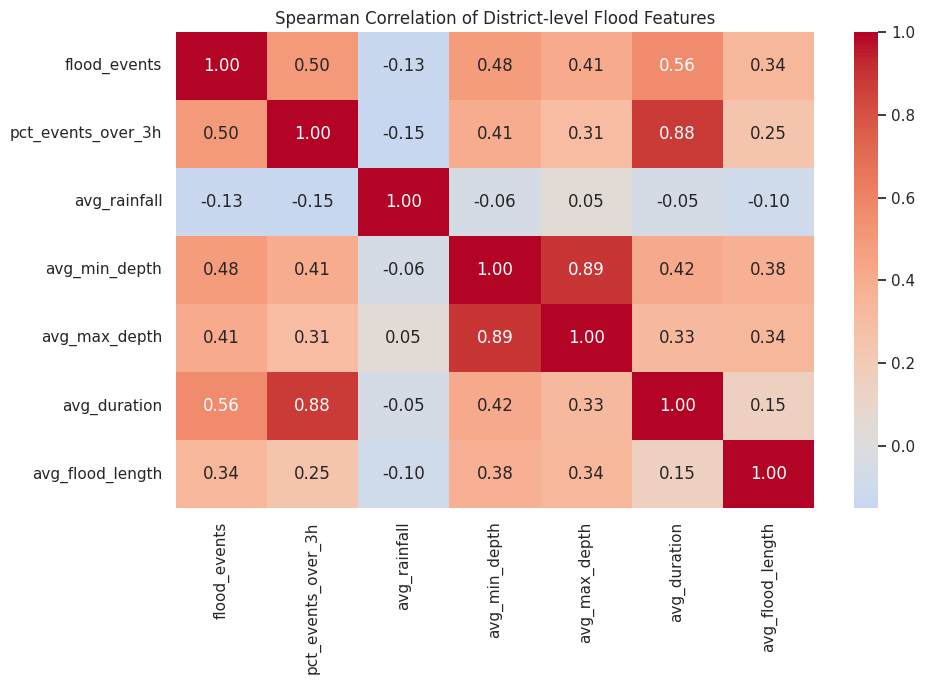

In [42]:
correlation_features = [
    "flood_events",
    "pct_events_over_3h",
    "avg_rainfall",
    "avg_min_depth",
    "avg_max_depth",
    "avg_duration",
    "avg_flood_length"
]

district_corr = district_features[
    correlation_features
].corr(method="spearman")

plt.figure(figsize=(10, 7))
sns.heatmap(
    district_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Spearman Correlation of District-level Flood Features")
plt.tight_layout()
plt.show()

**How I will use this result:** A strong correlation does not automatically mean that one feature must be removed. I will consider whether the variables describe the same dimension and whether keeping both changes the interpretation of the clusters.

For example, average minimum depth and average maximum depth may contain overlapping information. I will compare their relationships before deciding which depth measure to use as a K-Means input.

## 6. Build the district-level feature table for Part 6

Now I will merge the aggregated flood information with the master list of Bangkok districts.

The master list contains 50 districts, while flood records are available for 43 districts. The other seven districts have no recorded events in this dataset.

**Important:** No recorded events does not necessarily mean that a district never floods. I will keep these districts in the full district table for transparency, but I will not automatically treat their missing averages as zero or include them in the primary K-Means model.

In [43]:
district_data = ds[
    ["district_code", "district_th", "district_en"]
].merge(
    district_features,
    left_on="district_th",
    right_on="district",
    how="left"
)

district_data["no_recorded_events"] = (
    district_data["flood_events"].isna()
)

# Zero is meaningful for event counts only
district_data["flood_events"] = (
    district_data["flood_events"].fillna(0)
)
district_data["events_over_3h"] = (
    district_data["events_over_3h"].fillna(0)
)

print("Total districts in master list:", len(district_data))
print("Districts with recorded events:",
      district_data["district"].notna().sum())
print("Districts without recorded events:",
      district_data["no_recorded_events"].sum())

display(district_data.sort_values(
    "flood_events", ascending=False
))

Total districts in master list: 50
Districts with recorded events: 43
Districts without recorded events: 7


,district_code,district_th,district_en,district,flood_events,events_over_3h,avg_rainfall,avg_min_depth,avg_max_depth,avg_flood_length,flood_length_observations,avg_duration,median_duration,pct_events_over_3h,no_recorded_events
25,1026,ดินแดง,Din Daeng,ดินแดง,56.0,10.0,60.375000,11.696429,17.232143,269.642857,28.0,104.553571,80.0,17.857143,False
40,1041,หลักสี่,Lak Si,หลักสี่,52.0,4.0,66.086538,9.038462,14.230769,240.000000,30.0,82.365385,70.0,7.692308,False
29,1030,จตุจักร,Chatuchak,จตุจักร,47.0,14.0,73.936170,11.319149,16.659574,317.391304,23.0,133.085106,100.0,29.787234,False
26,1027,บึงกุ่ม,Bueng Kum,บึงกุ่ม,45.0,7.0,49.833333,11.666667,16.555556,219.047619,21.0,107.888889,85.0,15.555556,False
5,1006,บางกะปิ,Bang Kapi,บางกะปิ,44.0,16.0,73.784091,9.431818,14.431818,211.538462,26.0,188.136364,135.5,36.363636,False
36,1037,ราชเทวี,Ratchathewi,ราชเทวี,41.0,3.0,69.219512,10.853659,16.097561,200.952381,21.0,71.219512,60.0,7.317073,False
32,1033,คลองเตย,Khlong Toei,คลองเตย,36.0,2.0,67.694444,11.111111,15.750000,430.952381,21.0,82.222222,77.5,5.555556,False
41,1042,สายไหม,Sai Mai,สายไหม,35.0,3.0,54.428571,11.428571,17.185714,259.090909,22.0,68.800000,40.0,8.571429,False
10,1011,ลาดกระบัง,Lat Krabang,ลาดกระบัง,35.0,10.0,57.728571,11.029412,16.029412,288.636364,22.0,185.085714,140.0,28.571429,False
38,1039,วัฒนา,Watthana,วัฒนา,34.0,1.0,57.514706,12.205882,16.911765,401.851852,27.0,74.411765,62.5,2.941176,False


### Check missing values after district aggregation

Some districts have recorded flood events but no reported flooded road length. I should not replace a missing average road length with zero, because zero metres would mean something different from an unreported value.

I will inspect the missingness before deciding whether flood length can be included in the clustering feature set.

In [44]:
district_missing = pd.DataFrame({
    "Missing_Count": district_data.isna().sum(),
    "Missing_Percentage": (
        district_data.isna().mean() * 100
    ).round(2)
})

display(district_missing.sort_values(
    "Missing_Count", ascending=False
))

# Districts with recorded events but missing average road length
display(
    district_data[
        (district_data["flood_events"] > 0)
        & (district_data["avg_flood_length"].isna())
    ][["district_en", "flood_events",
       "flood_length_observations"]]
)

,Missing_Count,Missing_Percentage
avg_flood_length,11,22.0
avg_rainfall,7,14.0
district,7,14.0
flood_length_observations,7,14.0
avg_max_depth,7,14.0
avg_min_depth,7,14.0
avg_duration,7,14.0
pct_events_over_3h,7,14.0
median_duration,7,14.0
events_over_3h,0,0.0


,district_en,flood_events,flood_length_observations
7,Pom Prap Sattru Phai,3.0,0.0
15,Bangkok Yai,1.0,0.0
23,Rat Burana,1.0,0.0
24,Bang Phlat,1.0,0.0


**Interpretation:** Flood length is not reported for every event, so the district-level average is unavailable for some districts. I will not force this feature into the primary clustering model if it requires substantial imputation.

Instead, I will prepare a core feature set that is available for all 43 districts with recorded events, and keep flood length as an additional feature for a separate sensitivity analysis if appropriate.

## 7. Final feature selection for K-Means

For the first K-Means experiment in Part 6, I propose using these core features:

| Feature | Why I keep it |
|---|---|
| `flood_events` | Represents recorded flood frequency |
| `pct_events_over_3h` | Represents the proportion of prolonged events |
| `avg_rainfall` | Represents rainfall associated with recorded events |
| `avg_max_depth` | Represents average maximum flood depth |
| `avg_duration` | Represents average flood persistence |

I will not include both `events_over_3h` and `pct_events_over_3h` in the same initial feature set because the raw count is partly dependent on the total number of events.

I will also leave `avg_flood_length` out of the primary model because it is missing for some districts. We can test whether adding it changes the result using only districts with complete road-length information.

The features will be standardized before K-Means because they use different units and scales.

In [45]:
# Keep only districts with recorded flood events
districts_with_events = district_data[
    district_data["flood_events"] > 0
].copy()

core_features = [
    "flood_events",
    "pct_events_over_3h",
    "avg_rainfall",
    "avg_max_depth",
    "avg_duration"
]

X_district = districts_with_events[
    core_features
].copy()

print("Districts for primary clustering:",
      len(X_district))
print("Features for primary clustering:",
      X_district.columns.tolist())

print("Missing values in core feature matrix:")
display(X_district.isna().sum())

display(X_district.head())

Districts for primary clustering: 43
Features for primary clustering: ['flood_events', 'pct_events_over_3h', 'avg_rainfall', 'avg_max_depth', 'avg_duration']
Missing values in core feature matrix:


,0
flood_events,0
pct_events_over_3h,0
avg_rainfall,0
avg_max_depth,0
avg_duration,0


,flood_events,pct_events_over_3h,avg_rainfall,avg_max_depth,avg_duration
0,5.0,20.000000,86.200000,20.000000,79.200000
1,3.0,0.000000,59.166667,13.333333,43.333333
3,10.0,20.000000,58.850000,16.000000,174.500000
4,33.0,18.181818,59.348485,12.878788,118.212121
5,44.0,36.363636,73.784091,14.431818,188.136364


### Check feature distributions and scale

K-Means uses distance calculations, so variables with larger numerical values can dominate if I do not standardize them.

I will prepare the feature matrix here, but the actual K-Means model, Elbow Method, Silhouette Score, and cluster interpretation belong to **Part 6: Basic Machine Learning**.

In [46]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_district_scaled = pd.DataFrame(
    scaler.fit_transform(X_district),
    columns=core_features,
    index=districts_with_events["district_en"]
)

display(X_district_scaled.head())

print("Mean after standardization:")
display(X_district_scaled.mean().round(3))

print("Standard deviation after standardization:")
display(X_district_scaled.std(ddof=0).round(3))

,flood_events,pct_events_over_3h,avg_rainfall,avg_max_depth,avg_duration
district_en,,,,,
Phra Nakhon,-0.884695,0.209042,1.747905,2.093957,-0.464595
Dusit,-1.007808,-0.944299,-0.672772,-0.746951,-0.935282
Bang Rak,-0.576913,0.209042,-0.701128,0.389412,0.786053
Bang Khen,0.838886,0.104193,-0.656491,-0.940650,0.047372
Bang Kapi,1.516007,1.152684,0.636133,-0.278847,0.965006


Mean after standardization:


,0
flood_events,-0.0
pct_events_over_3h,0.0
avg_rainfall,-0.0
avg_max_depth,-0.0
avg_duration,0.0


Standard deviation after standardization:


,0
flood_events,1.0
pct_events_over_3h,1.0
avg_rainfall,1.0
avg_max_depth,1.0
avg_duration,1.0


## 8. Save the outputs for Part 6

I will save the district-level feature table and the standardized feature matrix. These will be the inputs for the K-Means analysis in the next part.

The original event-level data is still available in `df_raw`, while `df` is the deduplicated dataset used throughout this analysis.

In [47]:
district_data.to_csv(
    "district_flood_features_all_50.csv",
    index=False,
    encoding="utf-8-sig"
)

X_district.to_csv(
    "district_flood_features_for_kmeans.csv",
    encoding="utf-8-sig"
)

X_district_scaled.to_csv(
    "district_flood_features_scaled.csv",
    encoding="utf-8-sig"
)

print("Saved:")
print("- district_flood_features_all_50.csv")
print("- district_flood_features_for_kmeans.csv")
print("- district_flood_features_scaled.csv")

Saved:
- district_flood_features_all_50.csv
- district_flood_features_for_kmeans.csv
- district_flood_features_scaled.csv


# 9. Budget allocation exploration (separate from K-Means)

I also want to explore how the district-level flood patterns compare with the flood-management budgets.

However, this is a separate policy-oriented analysis. Budget amounts will **not** be used to create the K-Means clusters, because I want the clusters to represent flood characteristics rather than existing financial allocation.

I will compare budget amounts with recorded flood frequency and prolonged flooding. This can identify questions for further investigation, but it cannot prove whether a budget is sufficient or effective.

In [48]:
district_budget = bd[bd["level"] == "District"].copy()

budget_analysis = district_data.merge(
    district_budget[
        ["district_en", "budget_total", "budget_embarkment",
         "budget_drainage", "budget_operating",
         "budget_dredging", "budget_retention", "budget_pumps"]
    ],
    on="district_en",
    how="left"
)

display(
    budget_analysis[
        ["district_en", "flood_events", "events_over_3h",
         "pct_events_over_3h", "avg_duration", "budget_total"]
    ].sort_values("flood_events", ascending=False).round(2)
)

,district_en,flood_events,events_over_3h,pct_events_over_3h,avg_duration,budget_total
25,Din Daeng,56.0,10.0,17.86,104.55,87160616
40,Lak Si,52.0,4.0,7.69,82.37,694525825
29,Chatuchak,47.0,14.0,29.79,133.09,489673667
26,Bueng Kum,45.0,7.0,15.56,107.89,336442484
5,Bang Kapi,44.0,16.0,36.36,188.14,204014324
36,Ratchathewi,41.0,3.0,7.32,71.22,297632316
32,Khlong Toei,36.0,2.0,5.56,82.22,662579448
41,Sai Mai,35.0,3.0,8.57,68.80,91710300
10,Lat Krabang,35.0,10.0,28.57,185.09,266246800
38,Watthana,34.0,1.0,2.94,74.41,288210307


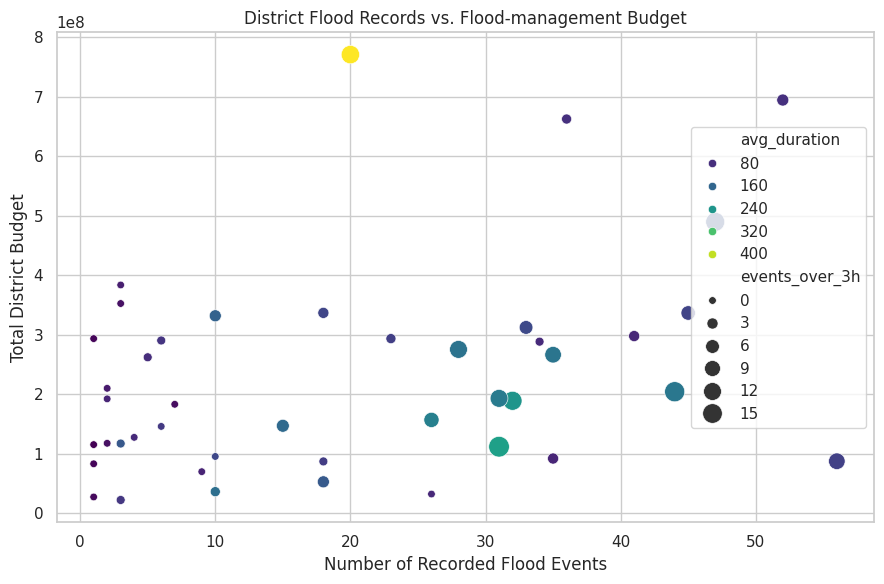

In [49]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=budget_analysis,
    x="flood_events",
    y="budget_total",
    hue="avg_duration",
    size="events_over_3h",
    sizes=(30, 220),
    palette="viridis"
)

plt.title("District Flood Records vs. Flood-management Budget")
plt.xlabel("Number of Recorded Flood Events")
plt.ylabel("Total District Budget")
plt.tight_layout()
plt.show()

**How I will interpret this:** I will look for districts with relatively high recorded flood frequency or prolonged flooding but comparatively lower budget allocation, and vice versa.

This is only an initial comparison. The total budget may cover multiple activities, and the dataset does not show the effectiveness, timing, or exact locations of each intervention. Therefore, I should describe any mismatch as a potential planning question rather than evidence of misallocation.

Possible next step: compare budget categories (drainage, dredging, pumps, retention, and embankment) with the district flood profiles.

# 10. Summary of Part 4

At this stage, I have moved from event-level exploration to a district-level feature table that can be used for K-Means clustering.

Before presenting the final findings, I should summarize the actual results generated by the notebook:

1. **Temporal pattern:** Which months and seasons contain the most recorded events?
2. **Persistence:** Which months or districts have a higher proportion of events lasting over three hours?
3. **District frequency:** Which districts have the highest number of recorded events?
4. **Flood characteristics:** How do rainfall, maximum depth, and duration differ across districts?
5. **Feature relationships:** Which district-level variables are strongly related or potentially redundant?
6. **ML preparation:** Which five features will be used as the initial K-Means inputs, and why?

**The key output of Part 4 is not the cluster labels yet.** It is the clean, interpretable district-level feature matrix. In Part 6, I will use this matrix to test different values of K, evaluate cluster separation, and interpret the resulting district groups.

*Now we have a clearer direction for the ML part. eiei. 😸*